# The `EE` Mechanism: Sequential Two-Electron Transfer

## 1. Goal

Model a sequential two-electron transfer (`EE` mechanism: $\text{A} + e^- \rightleftharpoons \text{B}$ at $E_1^0$, $\text{B} + e^- \rightleftharpoons \text{C}$ at $E_2^0$) using two `ElectrochemicalStep`s in `Mechanism`, and observe how $\Delta E^0 = E_1^0 - E_2^0$ controls wave separation vs. wave merging.

## 2. Physical Setup

We define species `A`, `B`, and `C` and test three regimes:
1. $\Delta E^0 = +0.30\text{ V}$ ($E_1^0 = +0.15\text{ V}, E_2^0 = -0.15\text{ V}$): two well-separated 1-$e^-$ waves.
2. $\Delta E^0 = +0.05\text{ V}$ ($E_1^0 = +0.025\text{ V}, E_2^0 = -0.025\text{ V}$): overlapping waves.
3. $\Delta E^0 = -0.15\text{ V}$ ($E_1^0 = -0.075\text{ V}, E_2^0 = +0.075\text{ V}$): potential inversion, merging into a single 2-$e^-$ wave.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato.geometry import PlanarGeometry
from softpotato.reactions import (
    ButlerVolmer,
    ElectrochemicalStep,
    Mechanism,
    Species,
)
from softpotato.techniques import CyclicVoltammetry, simulate

D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
k0 = 1.0e-2  # Fast quasi-reversible / near-Nernstian kinetics

sp_A = Species("A", diffusivity=D, bulk_concentration=c_bulk, n_electrons=1)
sp_B = Species("B", diffusivity=D, bulk_concentration=0.0, n_electrons=1)
sp_C = Species("C", diffusivity=D, bulk_concentration=0.0, n_electrons=1)
geometry = PlanarGeometry(area)
cv = CyclicVoltammetry(E_start=0.5, E_vertex1=-0.5, E_vertex2=0.5, scan_rate=0.1, dE=0.004)

cases = {
    "Separated (dE0 = +0.30 V)": (0.15, -0.15),
    "Overlapping (dE0 = +0.05 V)": (0.025, -0.025),
    "Merged / Inverted (dE0 = -0.15 V)": (-0.075, 0.075),
}

## 3. Simulation

We build each two-step `Mechanism` and simulate with `solver="scipy_ivp"`.

In [2]:
results = {}
for label, (E1, E2) in cases.items():
    mech = Mechanism(
        species=[sp_A, sp_B, sp_C],
        electrochemical_steps=[
            ElectrochemicalStep(sp_A, sp_B, ButlerVolmer(k0=k0, alpha=0.5, E0=E1, n=1)),
            ElectrochemicalStep(sp_B, sp_C, ButlerVolmer(k0=k0, alpha=0.5, E0=E2, n=1)),
        ],
    )
    results[label] = simulate(cv, mech, geometry=geometry, solver="scipy_ivp")

## 4. Diagnostics & Plots

We overlay the three `EE` voltammograms to compare peak separation and peak height.

Separated (dE0 = +0.30 V)          | I_pc =  -25.76 uA
Overlapping (dE0 = +0.05 V)        | I_pc =  -35.80 uA
Merged / Inverted (dE0 = -0.15 V)  | I_pc =  -52.37 uA


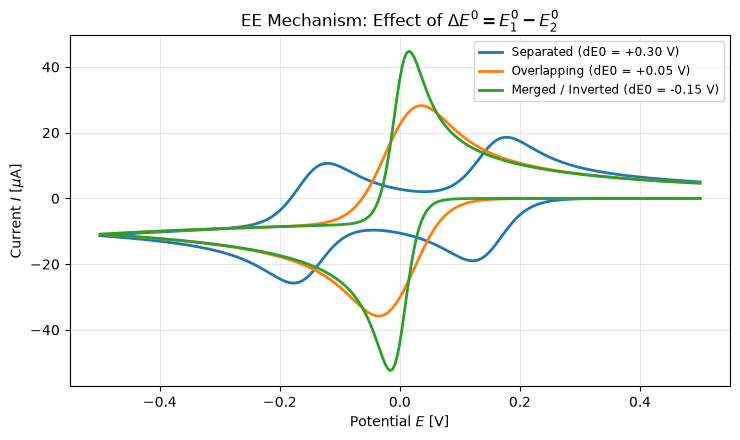

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, res in results.items():
    print(f"{label:34s} | I_pc = {res.current.min() * 1e6:7.2f} uA")
    ax.plot(res.potential, res.current * 1e6, lw=2, label=label)

ax.set_xlabel(r"Potential $E$ [V]")
ax.set_ylabel(r"Current $I$ [$\mu$A]")
ax.set_title(r"EE Mechanism: Effect of $\Delta E^0 = E_1^0 - E_2^0$")
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Key Takeaways

- When $E_1^0 - E_2^0 \gg RT/F$, two distinct 1-$e^-$ waves appear.
- When $E_2^0 > E_1^0$ (potential inversion), $\text{B}$ is immediately reduced to $\text{C}$ as soon as it forms, producing a single, sharper 2-$e^-$ wave with larger peak current ($\propto n^{3/2}$).
- **Next**: Explore [Catalytic EC' Mechanism](catalytic_ec.ipynb) or [Reaction Mechanisms Concepts](../../concepts/electrochemistry/mechanisms.md).